In [3]:
import importlib
import data

importlib.reload(data)

from data import clean_dataset

print(clean_dataset)

<function clean_dataset at 0x000001B9D2860CC0>


DATASET LOADED SUCCESSFULLY
--------------------------------------------------

Dataset Shape: (1000000, 20)

First 5 Rows:
   user_id product_id     category subcategory    brand     price  discount  \
0  U356787     P39256  Electronics      Mobile      H&M  33090.51     10.46   
1  U198246     P38657       Sports     Outdoor  Samsung   9368.97      5.32   
2  U539898     P38893       Sports     Fitness      H&M  14756.85     26.00   
3  U325772     P54118       Beauty      Makeup     Sony    668.83     24.81   
4  U865179     P70217         Home       Decor     Sony  10881.29     48.63   

   final_price  rating  review_count  stock seller_id  seller_rating  \
0     29629.31     4.9            43     71     S2679            4.3   
1      8870.73     3.9            13    119     S9279            4.9   
2     10919.43     4.2            46    229     S5557            4.9   
3       502.91     3.8             6     52     S2519            3.1   
4      5589.58     4.0            48    2

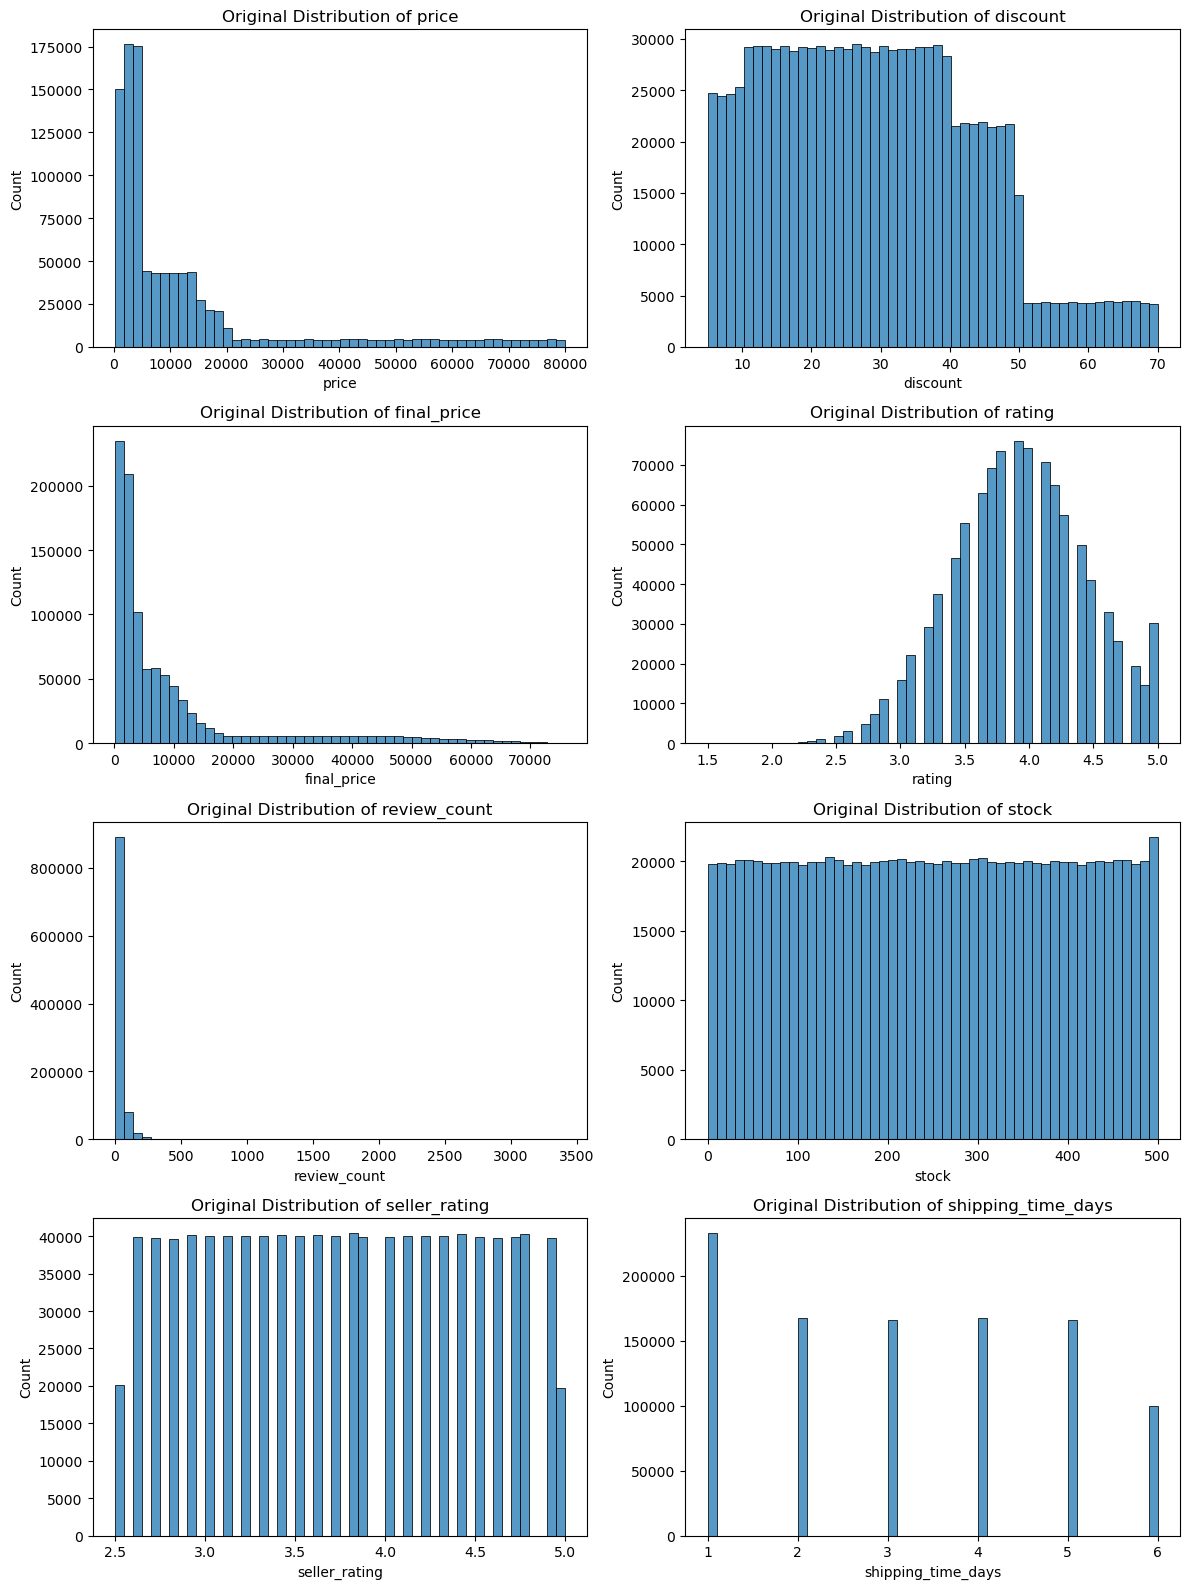


price:
Lower Bound: -14451.355
Upper Bound: 31285.985
Rows Removed: 129873

final_price:
Lower Bound: -7371.9825
Upper Bound: 16327.037499999999
Rows Removed: 30961

review_count:
Lower Bound: -33.5
Upper Bound: 82.5
Rows Removed: 65602


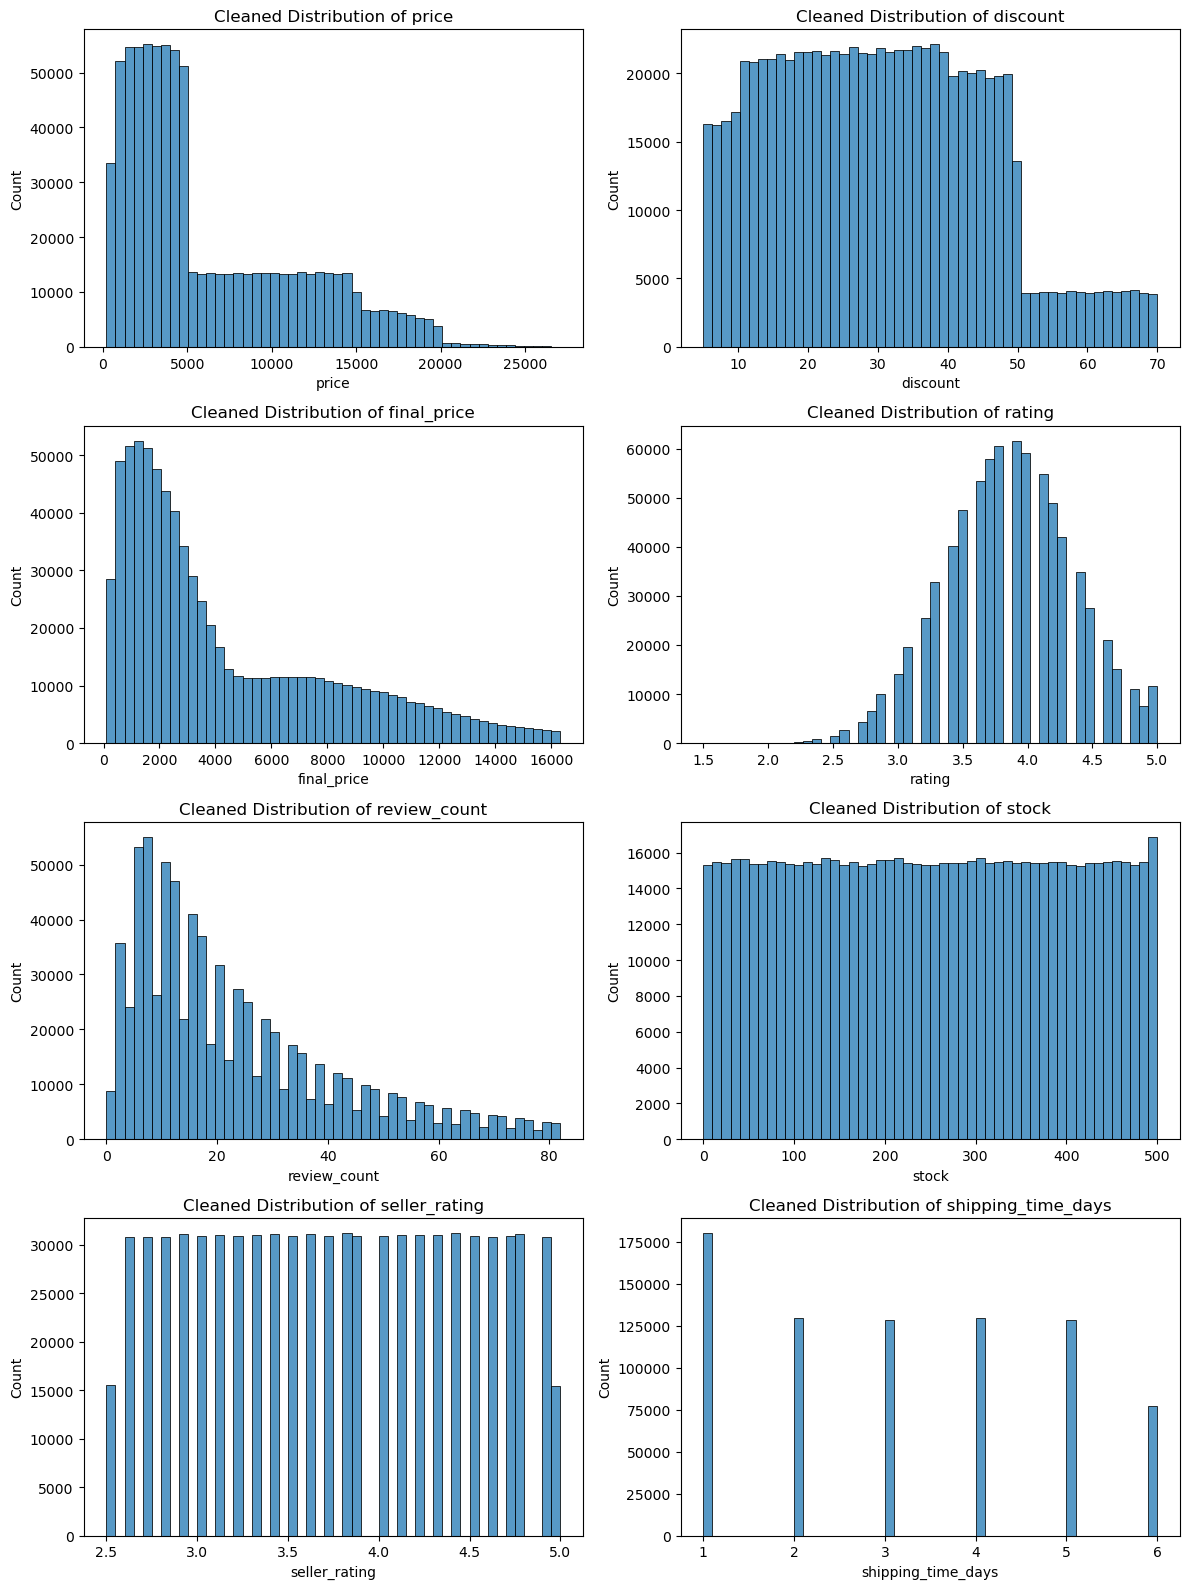


FINAL CLEANING SUMMARY
--------------------------------------------------
Final Shape: (773564, 20)
Remaining Missing Values:
user_id               0
product_id            0
category              0
subcategory           0
brand                 0
price                 0
discount              0
final_price           0
rating                0
review_count          0
stock                 0
seller_id             0
seller_rating         0
purchase_date         0
shipping_time_days    0
location              0
device                0
payment_method        0
is_returned           0
delivery_status       0
dtype: int64

Remaining Duplicates: 0


In [4]:
df_clean = clean_dataset(
    file_path="amazon_ecommerce_1m.csv",
    outlier_cols=['price', 'final_price', 'review_count'],
    factor=1.5,
    drop_duplicates=True,
    bins=50
)

In [5]:
pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.


In [6]:
from getpass import getpass
from sqlalchemy import create_engine, URL

password = getpass("Enter MySQL password: ")

connection_url = URL.create(
    "mysql+pymysql",
    username="root",
    password=password,
    host="localhost",
    port=3306,
    database="data_cleaning_project"
)

engine = create_engine(connection_url)

try:
    with engine.connect() as connection:
        print("Successfully connected to MySQL!")
except Exception as e:
    print("Connection failed:", e)

Enter MySQL password:  ········


Successfully connected to MySQL!


In [8]:
df_clean.to_sql(
    name="cleaned_data",
    con=engine,
    if_exists="replace",
    index=False
)

773564